# Notebook 04: Baselines Fortes, Diagnóstico e Ablação de Features

**Unidade Curricular:** Dados e Aprendizagem Automática (DAA) — 2026/2027

A referência do NB03 (árvore simples, Macro-F1 0.407) é fraca por construção: uma só árvore tem variância alta e, com profundidade 8, usa no máximo ~255 divisões para 409 features e 16 classes. Este notebook responde a três perguntas, por esta ordem: (1) quanto ganhamos só por trocar de família de modelo, sem mexer em features? (2) onde falha o melhor modelo — nas classes jovens pequenas? com erros ao lado (off-by-one) ou dispersos? (3) que blocos de features novas valem mesmo a pena?

Saídas: um novo baseline, um diagnóstico por classe e o conjunto de features vencedor, que segue para o Notebook_05 (encodings, formulações do alvo, tuning, submissão). A métrica em tudo é o **Macro F1** — a mesma do Kaggle — porque dá peso igual às 16 faixas etárias. Todas as comparações usam as *mesmas* folds: números obtidos em splits diferentes não são comparáveis entre si.


## 0. Configuração, dados e protocolo fixo

Carregamos duas vistas dos mesmos dados: `train_nb02.csv` (F0 = 409 features numéricas, prontas para modelos) e `train_nb01.csv` (texto original, de onde se contam códigos como "Não aplicável" e se somam respostas clínicas). Os índices `PID` têm de coincidir — o `assert` abaixo garante que nenhuma linha troca de pessoa entre as duas vistas, o que corromperia silenciosamente todas as features novas.

As 5 folds estratificadas são calculadas **uma única vez** (seed 42) e reutilizadas em todas as experiências deste e do próximo notebook. Estratificadas porque as classes pequenas (`18-19` tem 172 casos) podem desaparecer de um fold aleatório; fixas porque só assim a diferença entre dois modelos é sinal, e não sorte do split.


In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix

warnings.filterwarnings('ignore', category=FutureWarning)
plt.style.use('ggplot')
sns.set_theme(style='whitegrid')

DATA_DIR = '../data'
TARGET = 'AGE_RANGE'
RANDOM_STATE = 42
N_SPLITS = 5
N_EST_RF = 200

train_nb02 = pd.read_csv(os.path.join(DATA_DIR, 'train_nb02.csv'), index_col='PID')
train_nb01 = pd.read_csv(os.path.join(DATA_DIR, 'train_nb01.csv'), index_col='PID',
                           keep_default_na=False, na_values=[''])
test_nb02 = pd.read_csv(os.path.join(DATA_DIR, 'test_nb02.csv'), index_col='PID')
test_nb01 = pd.read_csv(os.path.join(DATA_DIR, 'test_nb01.csv'), index_col='PID',
                          keep_default_na=False, na_values=[''])

assert (train_nb02.index == train_nb01.index).all()
assert (test_nb02.index == test_nb01.index).all()

X_F0 = train_nb02.drop(columns=TARGET)
y = train_nb02[TARGET]
CLASSES = sorted(y.unique())
print('F0:', X_F0.shape, '| classes:', CLASSES)

FOLDS = list(StratifiedKFold(n_splits=N_SPLITS, shuffle=True,
                               random_state=RANDOM_STATE).split(X_F0, y))
print('folds fixas:', len(FOLDS), 'seed:', RANDOM_STATE)

F0: (10962, 409) | classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15)]
folds fixas: 5 seed: 42


In [2]:
def avaliar_cv(construtor, X, y, nome):
    f1s = []
    oof = np.empty(len(y), dtype=int)
    oof_proba = np.zeros((len(y), len(CLASSES)))
    tem_proba = True
    for tr, va in FOLDS:
        m = construtor()
        m.fit(X.iloc[tr], y.iloc[tr])
        oof[va] = m.predict(X.iloc[va])
        if hasattr(m, 'predict_proba'):
            oof_proba[va] = m.predict_proba(X.iloc[va])
        else:
            tem_proba = False
        f1s.append(f1_score(y.iloc[va], oof[va], average='macro'))
    f1s = np.array(f1s)
    return {'nome': nome, 'mean': float(f1s.mean()), 'std': float(f1s.std()),
            'folds': f1s, 'oof': oof, 'oof_proba': oof_proba if tem_proba else None}


def tabela_resultados(resultados):
    linhas = []
    for r in resultados:
        f1c = f1_score(y, r['oof'], average=None)
        piores = np.argsort(f1c)[:3]
        detalhe = ', '.join(str(int(CLASSES[i])) + ' (' + format(float(f1c[i]), '.2f') + ')'
                             for i in piores)
        linhas.append({'Modelo': r['nome'], 'Macro-F1': round(r['mean'], 4),
                        'dp': round(r['std'], 4), '3 piores classes': detalhe})
    return pd.DataFrame(linhas)


def plot_comparacao(resultados, titulo):
    df = pd.DataFrame([{'Modelo': r['nome'], 'Macro-F1': v}
                       for r in resultados for v in r['folds']])
    plt.figure(figsize=(9, 4))
    sns.barplot(data=df, x='Modelo', y='Macro-F1', errorbar='sd', capsize=0.15)
    plt.ylim(0, 0.7)
    plt.title(titulo)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


def plot_diagnostico(oof, titulo):
    cm = confusion_matrix(y, oof, labels=CLASSES, normalize='true')
    f1c = f1_score(y, oof, average=None)
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1, ax=ax[0])
    ax[0].set_title(titulo + ' - confusao (linhas normalizadas)')
    ax[0].set_xlabel('Previsto')
    ax[0].set_ylabel('Real')
    sns.barplot(x=list(CLASSES), y=list(f1c), hue=list(CLASSES), legend=False,
                palette='viridis', ax=ax[1])
    ax[1].axhline(float(f1c.mean()), ls='--', c='red')
    ax[1].set_title(titulo + ' - F1 por classe (media a tracejado)')
    ax[1].set_xlabel('Classe (AGE_RANGE)')
    plt.tight_layout()
    plt.show()
    piores = np.argsort(f1c)[:5]
    print('5 piores classes:', [(int(CLASSES[i]), round(float(f1c[i]), 3)) for i in piores])
    top = np.argsort(f1c)[-3:][::-1]
    print('3 melhores classes:', [(int(CLASSES[i]), round(float(f1c[i]), 3)) for i in top])

## 1. Baselines fortes sobre F0 (passo 1 do plano)

Testamos uma escada de complexidade, tudo sobre as mesmas 409 features e folds. A árvore `depth=8` é o sanity check: deve reproduzir ~0.407, provando que o protocolo está correto antes de acreditar em números novos. A RandomForest reduz a variância por bagging (200 árvores em paralelo); o HistGradientBoosting corrige erros sequencialmente e é, em geral, a família mais forte do sklearn para tabular.

Ambos levam `class_weight="balanced"` porque a métrica pesa as 16 classes por igual: o treino tem de fazer o mesmo, ou o modelo sacrifica as faixas jovens para acertar nas grandes. Todo o resto fica em defaults — afinar hiperparâmetros agora seria otimizar configurações que a ablação e os encodings vão deitar fora; o tuning vem por último, no NB05. Objetivo desta secção: um novo baseline realista (~0.50).


,Modelo,Macro-F1,dp,3 piores classes
0,Arvore depth=8 (ref NB03),0.4072,0.0057,"4 (0.18), 13 (0.21), 5 (0.29)"
1,RandomForest 200,0.4463,0.0043,"4 (0.25), 13 (0.26), 14 (0.32)"
2,HistGradientBoosting,0.4657,0.0053,"1 (0.27), 13 (0.28), 4 (0.30)"


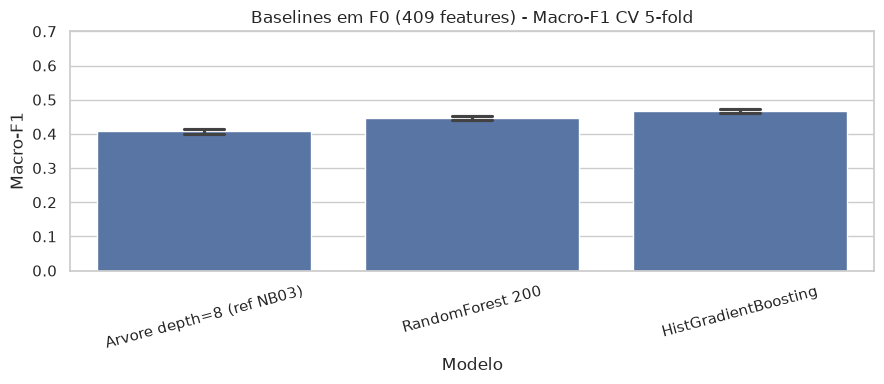

Modelo para a ablacao: HistGradientBoosting 0.4657


In [3]:
baselines = [
    avaliar_cv(lambda: DecisionTreeClassifier(max_depth=8, class_weight='balanced',
                                                random_state=RANDOM_STATE),
                 X_F0, y, 'Arvore depth=8 (ref NB03)'),
    avaliar_cv(lambda: RandomForestClassifier(n_estimators=N_EST_RF, class_weight='balanced',
                                               n_jobs=-1, random_state=RANDOM_STATE),
                 X_F0, y, 'RandomForest 200'),
    avaliar_cv(lambda: HistGradientBoostingClassifier(class_weight='balanced',
                                                       random_state=RANDOM_STATE),
                 X_F0, y, 'HistGradientBoosting'),
]
display(tabela_resultados(baselines))
plot_comparacao(baselines, 'Baselines em F0 (409 features) - Macro-F1 CV 5-fold')

MELHOR_BASE = max(baselines, key=lambda r: r['mean'])
print('Modelo para a ablacao:', MELHOR_BASE['nome'], round(MELHOR_BASE['mean'], 4))

## 2. Diagnóstico do melhor baseline (passo 2 do plano)

Números médios escondem onde dói. A matriz de confusão com linhas normalizadas lê-se assim: cada linha é uma classe real e a diagonal é o recall dessa classe — o ideal seria tudo na diagonal. A banda junto à diagonal são erros off-by-one (prever 60-64 em vez de 65-69): se dominarem, o alvo comporta-se como ordinal e vale a pena a formulação regressão/stacking do NB05. Erros dispersos longe da diagonal são confusão nominal, que se ataca com features e encodings.

O gráfico de F1 por classe (tracejado = média) mais a lista das 5 piores e 3 melhores classes diz quais faixas sustentam ou afundam o Macro-F1. Esperado: colapso nas jovens pequenas (0/1) e força nas centrais numerosas — a confirmar abaixo, porque é isso que `class_weight` e as escalas por classe tentam compensar.


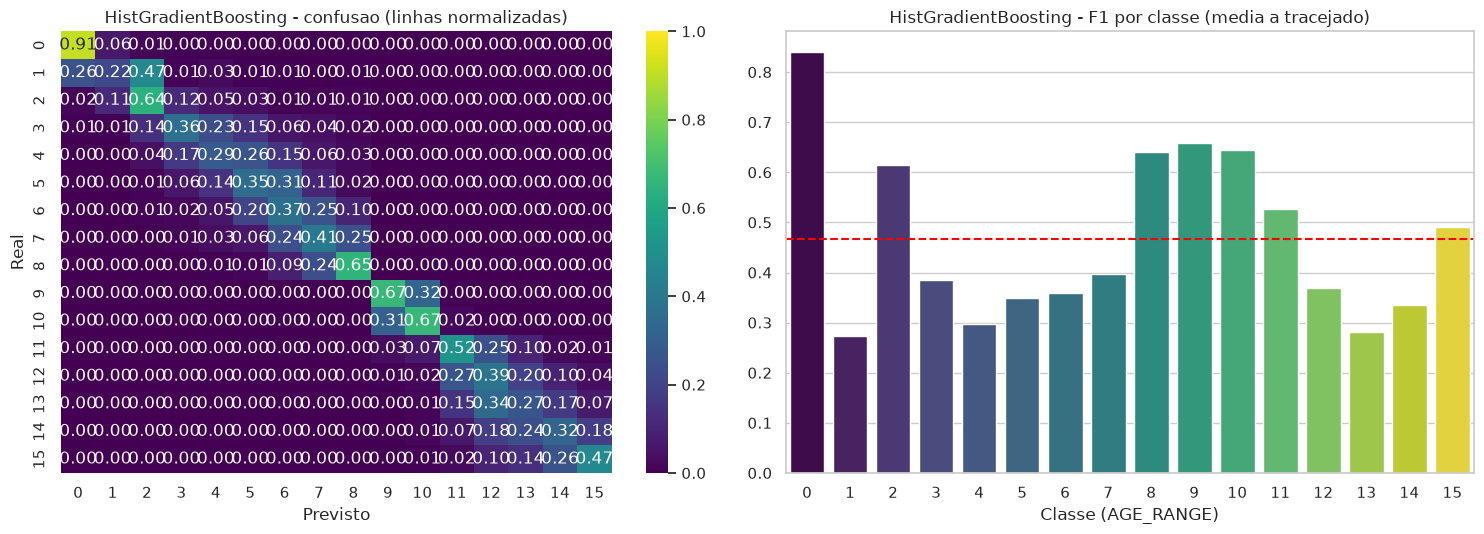

5 piores classes: [(1, 0.273), (13, 0.281), (4, 0.296), (14, 0.335), (5, 0.349)]
3 melhores classes: [(0, 0.839), (9, 0.658), (10, 0.644)]
Taxa de erro: 0.526
Off-by-one entre os erros: 4160 de 5767


In [4]:
plot_diagnostico(MELHOR_BASE['oof'], MELHOR_BASE['nome'])

err = (MELHOR_BASE['oof'] != y.values)
off1 = (np.abs(MELHOR_BASE['oof'] - y.values) == 1)
print('Taxa de erro:', round(float(err.mean()), 3))
print('Off-by-one entre os erros:', int(off1.sum()), 'de', int(err.sum()))

## 3. Blocos de features F1–F3 + ablação (passo 3 do plano)

**F1 (winsorização):** colunas como `IN59` (máx. 8000) e `IN55` (máx. 7000) têm caudas absurdas, provavelmente erros de registo, que distorcem os splits das árvores. Cortar a [p0.5, p99.5] preserva a ordem e tira alavanca aos outliers; o código −1 de falta é excluído do corte para não se misturar com valores reais.

**F2 (contagens):** número de "Não aplicável" e de "Sem resposta" por pessoa. São um proxy direto da carga de routing do questionário — e o NB01 mostrou que o routing anda com a idade (autonomia só perguntada a 55+). É sinal legítimo no Kaggle, mas declará-lo como limitação no relatório (ver plano §6).

**F3 (agregados clínicos):** contagem de comorbilidades `CD1*` e IMC de `BM1/BM2`. Uma árvore depth 8 nunca sintetiza sozinha "quantas doenças tem esta pessoa" a partir de 16 binárias dispersas; dar-lho feito é barato e clinicamente legível.

A ablação é **cumulativa** (F0 → +F1 → +F2 → +F3) sempre com o mesmo modelo e folds: cada linha da tabela atribui o ganho (ou a perda) a um bloco, que é exatamente a análise crítica pedida no relatório.


In [5]:
FLOAT_CLIP = ['IN2', 'IN3', 'IN4', 'HHNBPERS_COD', 'HHNBPERS_0_13_COD', 'HH_ACT',
              'HH_INACT', 'HO12_COD', 'HO34_COD', 'AM3', 'AM5', 'IN24', 'IN25', 'IN26',
              'BM1', 'BM2', 'PE2', 'PE4', 'PE6', 'PE7', 'PE8', 'PE9', 'IN29', 'DH2',
              'DH4', 'SK2', 'IN45', 'IN47', 'IN55', 'IN56', 'IN57', 'IN59', 'PA1_MESES']
LIMITES = {}
for c in FLOAT_CLIP:
    vv = X_F0[c]
    vv = vv[vv != -1]
    LIMITES[c] = (float(vv.quantile(0.005)), float(vv.quantile(0.995)))
print('IN59:', [round(v, 1) for v in LIMITES['IN59']])
print('IN55:', [round(v, 1) for v in LIMITES['IN55']])


def aplicar_clip(D):
    D = D.copy()
    for c, bounds in LIMITES.items():
        m = D[c] != -1
        D.loc[m, c] = D.loc[m, c].clip(bounds[0], bounds[1])
    return D


def bloco_F2(idx_tr, idx_te):
    txt_tr = train_nb01.select_dtypes(include='str')
    txt_te = test_nb01.select_dtypes(include='str')
    f_tr = pd.DataFrame({'N_NAO_APLICAVEL': (txt_tr == 'Não aplicável').sum(axis=1),
                         'N_SEM_RESPOSTA': ((txt_tr == 'Sem resposta') | (txt_tr == 'NR')).sum(axis=1)},
                        index=idx_tr)
    f_te = pd.DataFrame({'N_NAO_APLICAVEL': (txt_te == 'Não aplicável').sum(axis=1),
                         'N_SEM_RESPOSTA': ((txt_te == 'Sem resposta') | (txt_te == 'NR')).sum(axis=1)},
                        index=idx_te)
    return f_tr, f_te


def bloco_F3(Xb_tr, Xb_te):
    cd = [c for c in train_nb01.columns if c.startswith('CD1')]
    print('colunas CD1*:', len(cd))
    f_tr = pd.DataFrame({'N_CD_SIM': (train_nb01[cd] == 'Sim').sum(axis=1)}, index=Xb_tr.index)
    f_te = pd.DataFrame({'N_CD_SIM': (test_nb01[cd] == 'Sim').sum(axis=1)}, index=Xb_te.index)
    for f, Xb in ((f_tr, Xb_tr), (f_te, Xb_te)):
        ok = (Xb['BM1'] != -1) & (Xb['BM2'] != -1) & (Xb['BM1'] > 0)
        f['IMC'] = -1.0
        f.loc[ok, 'IMC'] = Xb.loc[ok, 'BM2'] / (Xb.loc[ok, 'BM1'] / 100) ** 2
    return f_tr, f_te


X_clip = aplicar_clip(X_F0)
X_test_clip = aplicar_clip(test_nb02[X_F0.columns])
f2_tr, f2_te = bloco_F2(X_F0.index, test_nb02.index)
f3_tr, f3_te = bloco_F3(X_F0, test_nb02)
print(f2_tr.describe().round(1).to_string())
print(f3_tr.describe().round(1).to_string())

IN59: [2.0, 439.2]
IN55: [2.0, 1436.5]
colunas CD1*: 16
       N_NAO_APLICAVEL  N_SEM_RESPOSTA
count          10962.0         10962.0
mean              65.3             1.7
std                8.5             5.9
min               29.0             0.0
25%               60.0             0.0
50%               66.0             0.0
75%               70.0             1.0
max              105.0           114.0
       N_CD_SIM      IMC
count   10962.0  10962.0
mean        2.6     25.3
std         2.5      6.8
min         0.0     -1.0
25%         0.0     22.9
50%         2.0     25.6
75%         4.0     28.8
max        13.0     54.0


,Modelo,Macro-F1,dp,3 piores classes
0,HistGradientBoosting | F0,0.4657,0.0053,"1 (0.27), 13 (0.28), 4 (0.30)"
1,HistGradientBoosting | F0+F1,0.4650,0.0039,"4 (0.29), 13 (0.29), 1 (0.29)"
2,HistGradientBoosting | F0+F1+F2,0.4628,0.0102,"4 (0.28), 13 (0.29), 1 (0.31)"
3,HistGradientBoosting | F0+F1+F2+F3,0.4657,0.0101,"13 (0.26), 4 (0.30), 14 (0.33)"


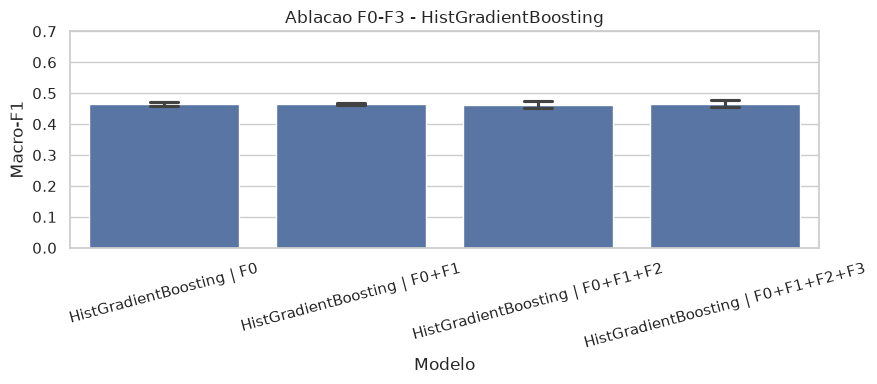

Segue para o NB05: HistGradientBoosting | F0+F1+F2+F3 0.4657


In [6]:
NOME_MELHOR = MELHOR_BASE['nome']


def construtor_melhor():
    if NOME_MELHOR.startswith('Hist'):
        return HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE)
    return RandomForestClassifier(n_estimators=N_EST_RF, class_weight='balanced',
                                  n_jobs=-1, random_state=RANDOM_STATE)


conjuntos = {
    'F0': (X_F0, None),
    'F0+F1': (X_clip, None),
    'F0+F1+F2': (pd.concat([X_clip, f2_tr], axis=1), pd.concat([X_test_clip, f2_te], axis=1)),
    'F0+F1+F2+F3': (pd.concat([X_clip, f2_tr, f3_tr], axis=1),
                   pd.concat([X_test_clip, f2_te, f3_te], axis=1)),
}
ablacao = [avaliar_cv(construtor_melhor, Xc, y, NOME_MELHOR + ' | ' + n)
           for n, (Xc, _) in conjuntos.items()]
display(tabela_resultados(ablacao))
plot_comparacao(ablacao, 'Ablacao F0-F3 - ' + NOME_MELHOR)

MELHOR_ABL = max(ablacao, key=lambda r: r['mean'])
print('Segue para o NB05:', MELHOR_ABL['nome'], round(MELHOR_ABL['mean'], 4))

## 4. Artefactos para o Notebook_05

O NB05 precisa de duas coisas que custam ~40 minutos a recalcular: qual foi o conjunto vencedor e as previsões out-of-fold do modelo vencedor (o tuning de thresholds faz-se sobre elas, sem retreinar). Guardamo-las em `data/` — gitignored, como os CSVs derivados — para a ponte entre notebooks ser um ficheiro, não uma reexecução.


In [7]:
import json

escolha = {'modelo': NOME_MELHOR, 'conjunto': MELHOR_ABL['nome'],
           'macro_f1_cv': round(float(MELHOR_ABL['mean']), 4)}
with open(os.path.join(DATA_DIR, 'nb04_escolha.json'), 'w') as f:
    json.dump(escolha, f)
np.savez(os.path.join(DATA_DIR, 'nb04_oof.npz'), oof=MELHOR_ABL['oof'],
         oof_proba=MELHOR_ABL['oof_proba'])
print('Guardado:', escolha)

Guardado: {'modelo': 'HistGradientBoosting', 'conjunto': 'HistGradientBoosting | F0+F1+F2+F3', 'macro_f1_cv': 0.4657}


## Conclusões

- **Novo baseline: HGB 0.4657 ± 0.005** (+5.9pp sobre os 0.407 da árvore; RF 0.446 no meio). A árvore reproduziu 0.4072, logo o protocolo está válido. Ficámos abaixo dos ~0.50 esperados — faltam encodings e formulações (NB05).

- **Piores classes:** 1 (18-19, F1 0.27), 13 (75-79, 0.28), 4 (30-34, 0.30). **Melhores:** 0 (15-17, 0.84 — trivial via routing/estudante), 9 e 10. O Macro-F1 é afundado pelas jovens pequenas e pelos 75-79, não pelo centro.

- **Erro 52.6%, dos quais 72% off-by-one:** banda junto à diagonal domina — sinal ordinal forte, que motiva diretamente a regressão/stacking do NB05 (D3).

- **Ablação sem ganho fora do dp:** F0 0.4657, +F1 0.4650, +F2 0.4628, +F3 0.4657. Winsorização inócua (HGB por bins já é robusto a outliers); F2 com ligeira queda, indistinguível de ruído. O conjunto completo empata com F0 e segue por desempate técnico; se o NB05 mostrar instabilidade, volta-se a F0 puro.

- **Segue para o NB05:** HistGradientBoosting | F0+F1+F2+F3 (0.4657). Nota: N_SEM_RESPOSTA chega a 114 por pessoa — possível cluster de não-respondentes, a explorar na EDA do relatório.